# Численное моделирование охлаждения процессора
**Стационарная теплопроводность в кубическом теплоотводе**

Цель — найти распределение температуры в теплоотводе и оценить температуру площадки контакта с процессором.

## 1. Геометрия и физические допущения
Теплоотвод — однородный куб со стороной $L$. В центре нижней грани $z=0$ расположена квадратная площадка
со стороной $a$, через которую процессор передаёт мощность $P$.
Внутри теплоотвода тепло не выделяется.

Для охлаждения выбираются грани $-X,+X,-Y,+Y,+Z$. На них вода имеет заданную температуру $T_w$,
а теплоотдача описывается постоянным коэффициентом $\alpha$. Остальная поверхность теплоизолирована.
Рассматривается установившийся режим; движение и нагрев воды отдельно не рассчитываются.

| Параметр | Обозначение | Значение по умолчанию |
|---|---|---:|
| Сторона теплоотвода | $L$ | 0,05 м |
| Сторона площадки нагрева | $a$ | 0,03 м |
| Мощность процессора | $P$ | 200 Вт |
| Теплопроводность | $\lambda$ | 200 Вт/(м·К) |
| Температура воды | $T_w$ | 20 °C |
| Коэффициент теплоотдачи | $\alpha$ | 2000 Вт/(м²·К) |
| Число ячеек по каждой оси | $N$ | 16 |

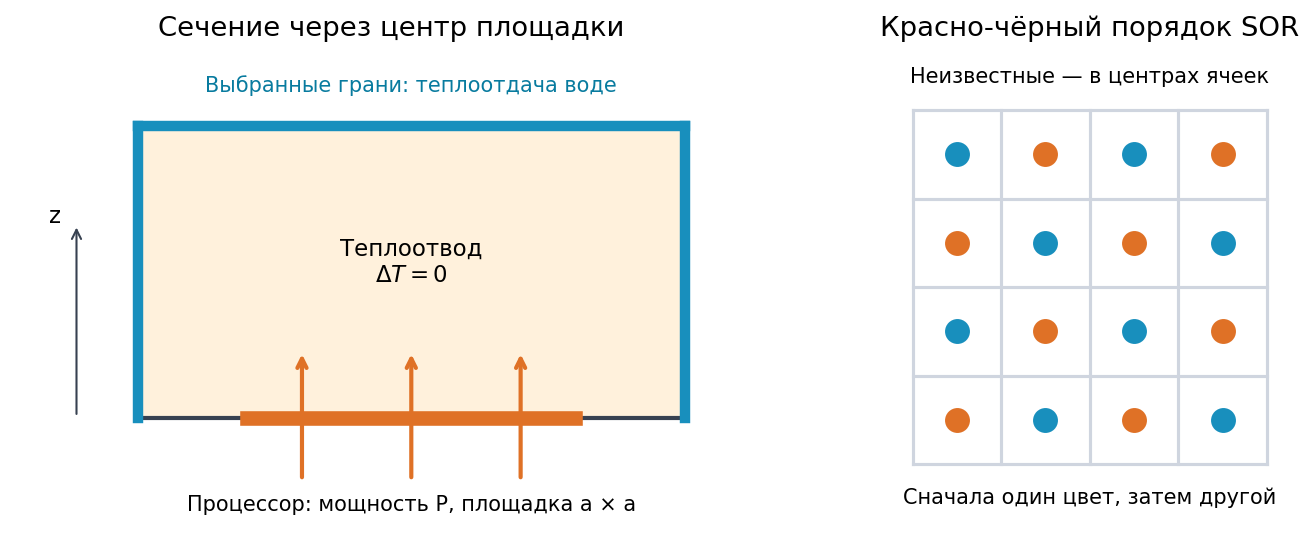

*Слева показан пример выбора охлаждаемых граней; снизу нагревается только центральная площадка. Справа — сечение раскраски трёхмерной сетки.*

## 2. Математическая постановка
Плотность теплового потока определяется законом Фурье:
$$\mathbf j=-\lambda\nabla T.$$

В установившемся режиме тепло не накапливается. Поскольку внутри материала нет источников, для любого объёма $V$ внутри теплоотвода суммарный выходящий поток равен нулю. По теореме Гаусса — Остроградского:
$$\oint_{\partial V}\mathbf j\cdot\mathbf n\,dS
=\int_V\operatorname{div}\mathbf j\,dV=0.$$
Из произвольности $V$ следует $\operatorname{div}\mathbf j=0$. При постоянной теплопроводности $\lambda$ закон Фурье даёт
$$\boxed{\Delta T=0.}$$

Граничные условия задают обмен теплом через внешнюю поверхность. Здесь $\mathbf n$ — внешняя нормаль, поэтому $\mathbf j\cdot\mathbf n$ положителен при выходе тепла из куба.

| Участок | Физическое условие | Формула |
|---|---|---|
| Площадка процессора | Мощность $P$ равномерно поступает внутрь через площадь $a^2$ | $-\lambda\,\partial T/\partial n=-P/a^2$ |
| Охлаждаемые грани | Закон теплоотдачи Ньютона | $-\lambda\,\partial T/\partial n=\alpha(T-T_w)$ |
| Остальная поверхность | Тепло не проходит через границу | $\partial T/\partial n=0$ |

Для расчёта вводим $u=T-T_w$. Поскольку температура воды постоянна, $\Delta u=0$, а на охлаждаемой поверхности $\mathbf j\cdot\mathbf n=\alpha u$.


## 3. Дискретизация: баланс тепла в ячейке
Куб делим на $N^3$ ячеек со стороной $h=L/N$. Неизвестная $u_p=u_{i,j,k}$ — превышение температуры в центре ячейки над температурой воды.

**Обмен между соседними ячейками.** По закону Фурье мощность равна теплопроводности, умноженной на площадь грани $h^2$ и на перепад температуры, делённый на расстояние между центрами $h$:
$$Q_{p\to q}\approx\lambda h^2\frac{u_p-u_q}{h}
=\lambda h(u_p-u_q).$$
Положительное значение означает выход тепла из ячейки $p$.

У внутренней ячейки шесть соседей. Из условия отсутствия накопления тепла:
$$\sum_{q\in\mathcal N(p)}Q_{p\to q}=0
\quad\Longrightarrow\quad
\boxed{6u_p-\sum_{q\in\mathcal N(p)}u_q=0.}$$
Это сеточный баланс потоков (метод конечных объёмов); для внутренней ячейки он совпадает с центральной разностной аппроксимацией $\Delta u=0$.

**Отвод тепла в воду.** От центра граничной ячейки тепло проходит через слой материала толщиной $h/2$, затем передаётся воде. Обозначим превышение температуры поверхности над температурой воды через $u_s$. По закону Фурье и закону теплоотдачи через оба участка проходит одна и та же мощность:
$$Q_f=\lambda h^2\frac{u_p-u_s}{h/2},
\qquad Q_f=\alpha h^2u_s.$$
Выражая перепады температуры и складывая их, получаем
$$u_p=(u_p-u_s)+u_s
=\frac{Q_f}{h^2}\left(\frac{h}{2\lambda}+\frac1\alpha\right).$$
Следовательно,
$$\boxed{Q_f=\frac{h^2u_p}{h/(2\lambda)+1/\alpha}
=\lambda h\beta u_p,\qquad
\beta=\frac{1}{1/2+\lambda/(\alpha h)}.}$$
Через теплоизолированную грань мощность равна нулю.

**Подвод тепла от процессора.** Плотность входящей мощности равна $P/a^2$. Если $S_{ij}$ — площадь пересечения площадки нагрева с нижней гранью ячейки, то
$$\boxed{P_{ij}=\frac{P}{a^2}S_{ij}.}$$
Так как $\sum_{ij}S_{ij}=a^2$, полная подведённая мощность сохраняется: $\sum_{ij}P_{ij}=P$.

**Общее уравнение ячейки.** Сумма мощностей, уходящих к соседям и в воду, равна подведённой мощности $P_p$:
$$\lambda h\sum_{q\in\mathcal N(p)}(u_p-u_q)
+m_p\lambda h\beta u_p=P_p,$$
где $m_p$ — число охлаждаемых внешних граней этой ячейки. После деления на $\lambda h$:
$$\boxed{d_pu_p-\sum_{q\in\mathcal N(p)}u_q=b_p,\qquad
 d_p=n_p+m_p\beta,\qquad b_p=\frac{P_p}{\lambda h}.}$$
Здесь $n_p$ — число реальных соседних ячеек; $P_p=P_{ij}$ в нижнем слое и $P_p=0$ в остальных слоях. Все уравнения вместе образуют СЛАУ $A\mathbf u=\mathbf b$.


## 4. Итерационное решение СЛАУ
Из уравнения ячейки выражаем её температуру через температуры соседей:
$$u_p=\frac{\sum_{q\in\mathcal N(p)}u_q+b_p}{d_p}.$$
Эта формула лежит в основе итерационных методов. Полную матрицу хранить не требуется: функция `neighbors(u)` вычисляет сумму температур соседей.

**Метод Якоби.** В правую часть подставляем значения предыдущей итерации:
$$u_p^{(m+1)}=\frac{\sum_{q\in\mathcal N(p)}u_q^{(m)}+b_p}{d_p}.$$


In [ ]:
# Одна итерация Якоби
u = (self.neighbors(u) + b) / d

**Метод Зейделя.** При обновлении ячейки используем уже вычисленные значения соседей. В программе ячейки разделены на два цвета по чётности $i+j+k$: сначала обновляется один цвет, затем другой. Все соседи имеют противоположный цвет.

**Метод SOR.** Поправку Зейделя умножаем на параметр $\omega$:
$$\boxed{u_p\leftarrow u_p+\omega\left(
\frac{\sum_{q\in\mathcal N(p)}u_q+b_p}{d_p}-u_p\right).}$$
При $\omega=1$ получаем метод Зейделя; при $1<\omega<2$ — верхнюю релаксацию. В программе применяется тот же порядок обновления по цветам.


In [ ]:
# Основной цикл SOR из thermal_model.py
u = np.zeros_like(b)
masks = [parity == 0, parity == 1]

for it in range(1, maxiter + 1):
    for mask in masks:
        candidate = (self.neighbors(u) + b) / d
        u[mask] += omega * (candidate[mask] - u[mask])

    r = self.residual(u, d, b)
    if r < eps:
        break

В приложении используется SOR с параметрами $\omega=1{,}97$ и $\varepsilon=10^{-8}$.


In [ ]:
u, history = model.sor(d, b, parity, omega=1.97, eps=1e-8)

## 5. Проверка решения
**Критерий остановки.** Точное решение СЛАУ удовлетворяет $\mathbf b-A\mathbf u=0$. Поэтому итерации продолжаем, пока относительная невязка не станет меньше $\varepsilon=10^{-8}$:
$$r=\frac{\|\mathbf b-A\mathbf u\|_\infty}{\|\mathbf b\|_\infty}
=\frac{\max_p\left|b_p+\sum_{q\in\mathcal N(p)}u_q-d_pu_p\right|}{\max_p|b_p|}
<\varepsilon.$$

**Баланс мощности.** Складывая уравнения всех ячеек, получаем сокращение внутренних потоков: $Q_{p\to q}=-Q_{q\to p}$. Поэтому полная мощность, отведённая в воду, должна равняться мощности процессора:
$$Q_f^{\mathrm{грань}}=\lambda h\beta\sum_{p\text{ у грани }f}u_p,
\qquad \sum_fQ_f^{\mathrm{грань}}=P.$$
В программе допустимое относительное расхождение составляет $10^{-5}$:
$$\frac{\left|\sum_fQ_f^{\mathrm{грань}}-P\right|}{P}\leq10^{-5}.$$

Невязка характеризует решение СЛАУ. Погрешность сеточной модели оценивают отдельно — сравнением результатов при сгущении сетки.


## 6. Температура контактной площадки
Температуры в центрах ячеек восстанавливаем по определению $u$:
$$T_p=T_w+u_p.$$

Чтобы оценить температуру нижней поверхности, учитываем перепад на расстоянии $h/2$ от поверхности до центра ячейки. По закону Фурье при среднем входящем потоке $P_{ij}/h^2$:
$$T^{\mathrm{конт}}_{ij}-T_{ij0}
\approx\frac{P_{ij}}{h^2}\frac{h/2}{\lambda}.$$
Отсюда используемая в программе оценка:
$$\boxed{T^{\mathrm{конт}}_{ij}=T_w+u_{ij0}+\frac{P_{ij}}{2\lambda h}.}$$
Поверхность нагрева горячее центра ячейки, поэтому поправка положительна. Для ячеек, частично перекрытых площадкой, это оценка по потоку, усреднённому по всей грани ячейки.